# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching,
so the branching-only correlation and modules notebooks are not produced — this
unconditional expression notebook follows signatures directly.)*

Per the **derive-don't-inherit** mandate we do not inherit Puram's SNAI1/ZEB1 pair:
we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus
the mesenchymal / neural-crest FOXC and PRRX families** — along this trajectory
(pSom/Gast-high origin → neural-crest terminus) and let the data choose the most
end-specific factor at each end, gated on detectable expression. VIM is a
mesenchymal marker, not a TF, and is excluded. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Ledergor2018_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Ledergor2018_Hematologic | category: Hematologic


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 8182 | pseudotime range 0.0 -> 9.9


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the
early (root) vs late (terminus) pseudotime tercile, and Spearman correlation with
pseudotime. Most negative correlation marks the root end; most positive marks the
terminus. Multiple-myeloma plasma cells barely run canonical EMT-TF programs, so
most of the panel is undetectable (FOXC/TWIST/SNAI2/PRRX2 expressed in <5 cells
each and dropped at gene filtering); only ZEB1/ZEB2 clear a 1% detection floor, so
those two are overlaid — the honest EMT-TF readout for this dataset.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.01   # detectable-expression floor (myeloma EMT-TFs are very sparse)
ok = df[df.frac_expr > FLOOR].sort_values('rho_vs_t')
print(f'\ndetectably-expressed EMT-TFs (frac_expr > {FLOOR}):', list(ok.TF))
early_tf = ok.iloc[0]['TF']
rest = ok[ok.TF != early_tf]                 # enforce two DISTINCT factors
late_tf = rest.iloc[-1]['TF'] if len(rest) else ok.iloc[-1]['TF']
print(f'derived pair: {early_tf} (early/root end) <-> {late_tf} (late/terminus end)')

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
PRRX1      0.000       0.000      0.000    -0.004 LATE(terminus)
SNAI1      0.000       0.000      0.000     0.015 LATE(terminus)
 ZEB1      0.033       0.020      0.024     0.030 LATE(terminus)
 ZEB2      0.015       0.002      0.011     0.043 LATE(terminus)

detectably-expressed EMT-TFs (frac_expr > 0.01): ['ZEB1', 'ZEB2']
derived pair: ZEB1 (early/root end) <-> ZEB2 (late/terminus end)


### EMT-TF expression overlay (deliverable)
House style — `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Categorical
overlay of thresholded expressers on a grey manifold (not a continuous single-gene
colormap): each factor thresholded at the upper quartile among its expressing
cells, drawn most-abundant-first so neither marker is occluded.

ZEB1: 3.3% expressing; 67 shown (upper quartile), mean pseudotime of shown = 0.53
ZEB2: 1.5% expressing; 30 shown (upper quartile), mean pseudotime of shown = 0.75
EMT-TFs shown: ZEB1 + ZEB2 | saved expression.pdf


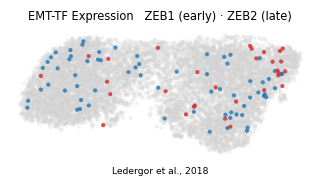

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Ledergor et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), mean pseudotime of shown = {tn[m].mean():.2f}')
print('EMT-TFs shown:', early_tf, '+', late_tf, '| saved expression.pdf')